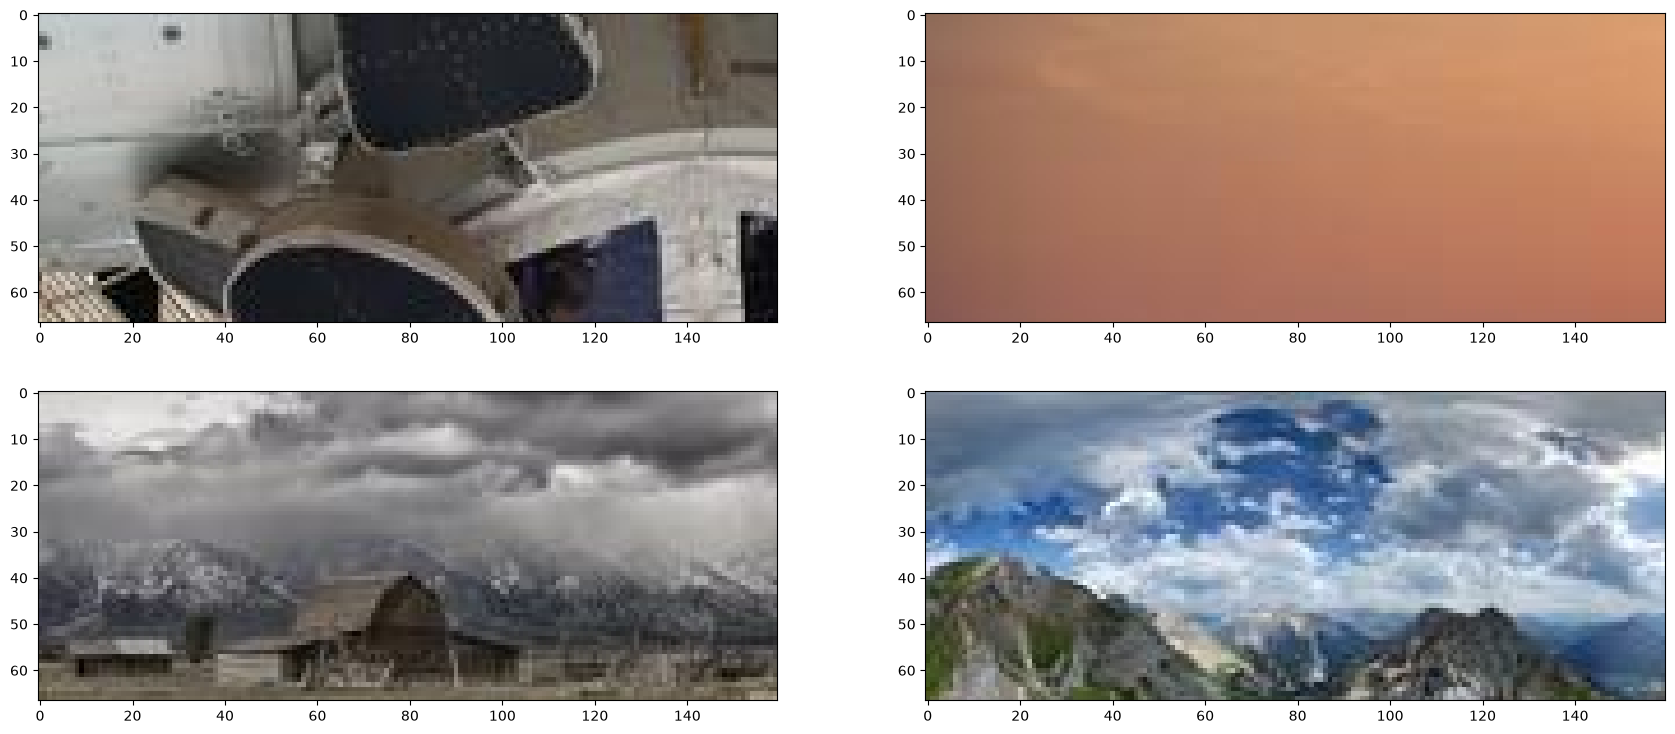

In [1]:
import os
import cv2
import numpy as np
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import keras
keras.utils.set_random_seed(1234)

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [21, 9]

from dataset import Dataset
ds = Dataset()
val = ds.validation()
x = np.empty((0, Dataset.SAMPLE_HEIGHT, Dataset.SAMPLE_WIDTH, 3), np.uint8)
y = np.empty((0, 2 * Dataset.SAMPLE_HEIGHT, 2 * Dataset.SAMPLE_WIDTH, 3), np.uint8)
for i in range(0, 4):
    _x, _y = next(val)
    x = np.concatenate((x, _x), axis=0)
    y = np.concatenate((y, _y), axis=0)

# show original (to be upscaled) images
for i in range(0, len(x)):
    plt.subplot(2, 2, i+1), plt.imshow(cv2.cvtColor(x[i], cv2.COLOR_BGR2RGB))

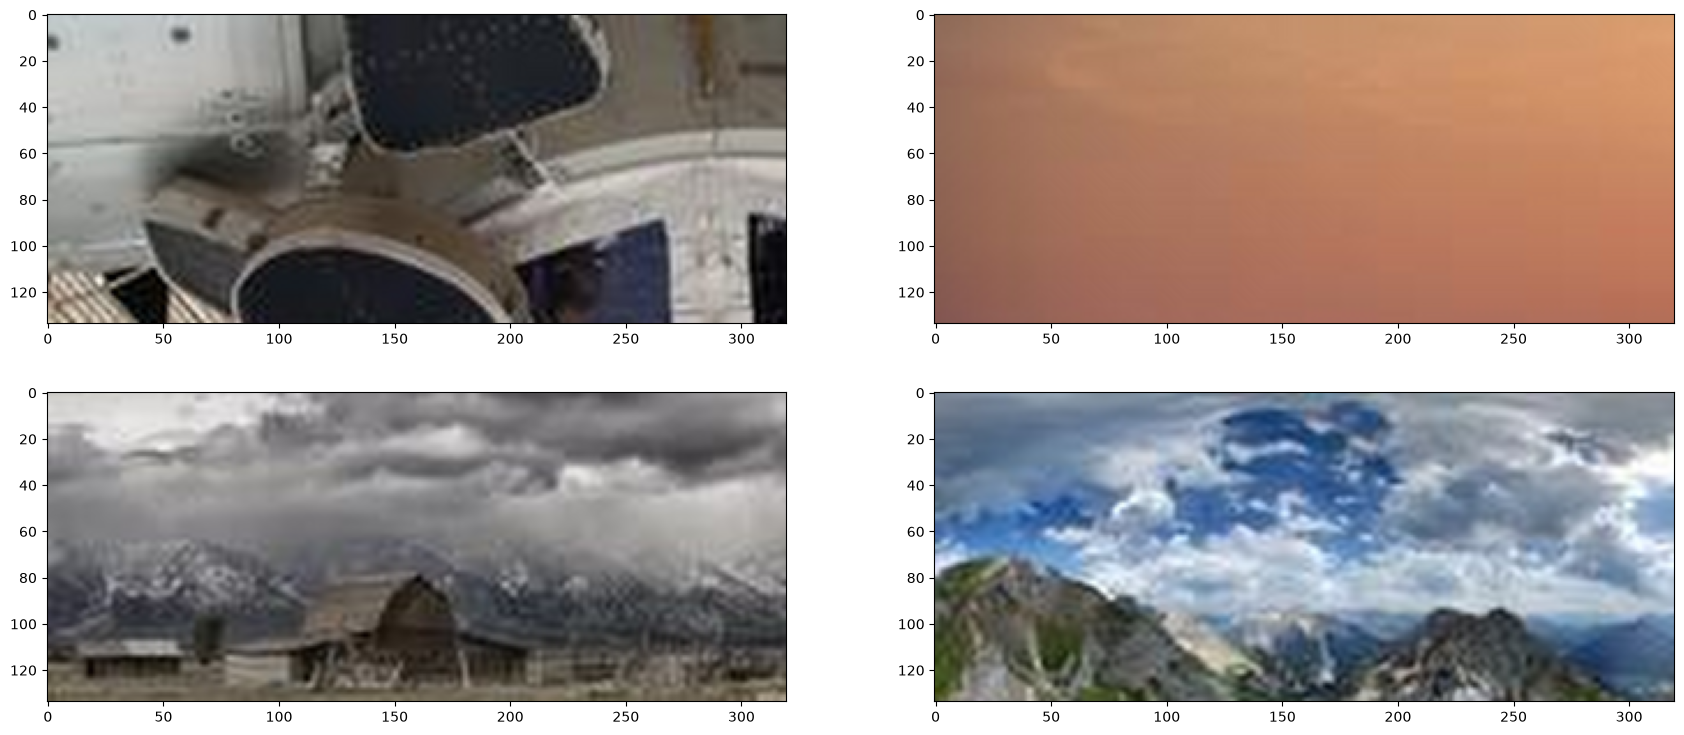

In [2]:
# show original images upscaled to 2x with cv2
resized_x = [np.clip(cv2.resize(x, None, fx=2, fy=2, interpolation=cv2.INTER_LANCZOS4), 0, 1) for x in x]
for i in range(0, len(x)):
    plt.subplot(2, 2, i+1), plt.imshow(cv2.cvtColor(resized_x[i], cv2.COLOR_BGR2RGB))

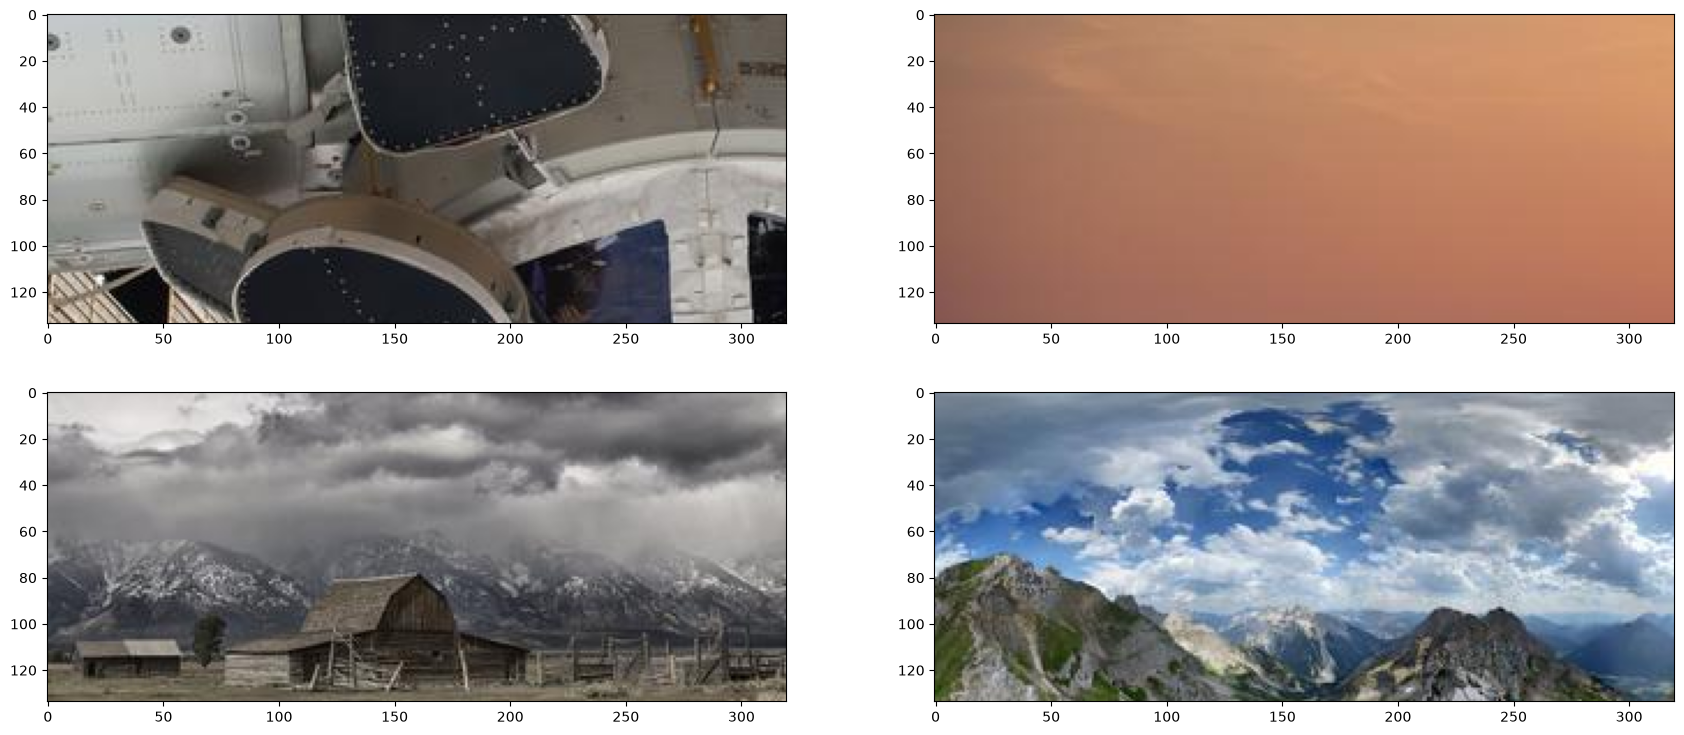

In [3]:
# show original 2x scaled images
for i in range(0, len(y)):
    plt.subplot(2, 2, i+1), plt.imshow(cv2.cvtColor(y[i], cv2.COLOR_BGR2RGB))